PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
all_df= pd.read_csv("Data/cleaned_merged_df.csv")

In [ ]:
betting_data_df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/yxy481/statistical-analysis-and-modeling-of-football-data/Football-data-website/Data/betting_data.csv'))


In [8]:
betting_data_df

,id,Bet Chance_home,Bet Chance_draw,Bet Chance_away
0,81,0.609756,0.245700,0.165563
1,82,0.549451,0.257732,0.212766
2,83,0.571429,0.265957,0.183824
3,84,0.558659,0.267380,0.196078
4,85,0.406504,0.294985,0.318471
...,...,...,...,...
3415,22270,0.613497,0.215517,0.200401
3416,22271,0.884956,0.093545,0.061463
3417,22272,0.321543,0.250627,0.456621
3418,22273,0.934579,0.066622,0.035920


In [9]:
all_df = pd.merge(all_df, betting_data_df, on="id", how="left")

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.multiclass import unique_labels

# This i s the preperation part, please refer to the feature lists to see differen feature families and sources
df = all_df.copy()
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df = df.sort_values('date').reset_index(drop=True)

TARGET = 'result'  # target column
label_order = ['W','D','L']  # labels

# Feature lists
original_features = ['DEEP', 'PPDA', 'xG','red_card', 'key_passes', 'xGBuildup', 'Corner kicks', 'Fouls',
 'Shots off target', 'Throw-ins', 'Ground duels', 'Aerial duels', 'Blocked per shots on target', 'Shots on target per total shots',
 'Hit woodwork per total shots', 'Shots outside box per total shots', 'Fouled in final third', 'Tackles won', 'Dribbles',
 'Crosses', 'Long balls', 'Yellow cards', 'Offsides', 'Goalkeeper saves']
window_aggregated_features = ['xG_median',
 'key_passes_median',
 'xGBuildup_median',
 'red_card_median',
 'DEEP_mean',
 'PPDA_median',
 'Corner kicks_mean',
 'Fouls_mean',
 'Shots off target_mean',
 'Throw-ins_mean',
 'Ground duels_mean',
 'Aerial duels_mean',
 'Blocked per shots on target_median',
 'Shots on target per total shots_mean',
 'Hit woodwork per total shots_median',
 'Shots outside box per total shots_mean',
 'Fouled in final third_mean',
 'Tackles won_mean',
 'Dribbles_mean',
 'Crosses_mean',
 'Long balls_median',
 'Yellow cards_mean',
 'Offsides_median',
 'Goalkeeper saves_mean']
model_aggregated_features  = ['xG_agg',
 'red_card_agg',
 'key_passes_agg',
 'xGBuildup_agg',
 'PPDA_agg',
 'DEEP_agg',
 'Corner kicks_agg',
 'Fouls_agg',
 'Shots off target_agg',
 'Throw-ins_agg',
 'Ground duels_agg',
 'Aerial duels_agg',
 'Blocked per shots on target_agg',
 'Shots on target per total shots_agg',
 'Hit woodwork per total shots_agg',
 'Shots outside box per total shots_agg',
 'Fouled in final third_agg',
 'Tackles won_agg',
 'Dribbles_agg',
 'Crosses_agg',
 'Long balls_agg',
 'Yellow cards_agg',
 'Offsides_agg',
 'Goalkeeper saves_agg']
fifa_features = ['Overall','Finishing_adj','Shot Power_adj','Long Shots_adj','Heading_adj','Curve_adj','FK Acc._adj','Penalties_adj','Short Pass_adj','Long Pass_adj','Stand Tackle_adj','Interceptions_adj','Jumping_adj','Stamina_adj','Strength_adj','Acceleration_adj','Agility_adj','Balance_adj','GK Handling_adj','GK Kicking_adj','GK Positioning_adj','Reactions_adj','Att. Position_adj','Vision_adj','Dribbling_adj','Overall Passing_adj','Overall Shooting_adj','Overall Defence_adj','Overall Physical_adj','Overall Goalkeeper_adj']
elo_features = ["ClubELO", "Seasonal_Elo"]

# Feature families for different modeling approaches
features_train_orig = original_features + fifa_features + elo_features
features_win        = window_aggregated_features + fifa_features + elo_features
features_agg        = model_aggregated_features  + fifa_features + elo_features

# --- 2) Time-based split to avoid leakage ---
cut = int(len(df) * 0.8)
train_df = df.iloc[:cut].copy()
test_df  = df.iloc[cut:].copy()


# --- 3) Helper: fit & evaluate ---
def fit_rf(X, y):
    # Balanced to help with class imbalance (draws are often rare)
    model = RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    model.fit(X, y)
    return model

def evaluate(model, X, y_true, title=""):
    y_pred = model.predict(X)
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average='macro')
    print(f"\n=== {title} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}")
    print(classification_report(y_true, y_pred, labels=label_order, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=label_order)
    print("Confusion Matrix [rows:true, cols:pred]:")
    print(pd.DataFrame(cm, index=label_order, columns=label_order))

# --- 4) Baseline: train & test on ORIGINAL features ---
X_train_orig = train_df[features_train_orig]
y_train      = train_df[TARGET].astype(str)

X_test_orig  = test_df[features_train_orig]
y_test       = test_df[TARGET].astype(str)

rf_orig = fit_rf(X_train_orig, y_train)
evaluate(rf_orig, X_test_orig, y_test, title="RF trained on ORIGINAL, tested on ORIGINAL")


# Mapping each original feature to its aggregated (model or window) counterpart so shapes match.
agg_proxy_map = {
    'DEEP':'DEEP_agg',
    'PPDA':'PPDA_agg',
    'xG':'xG_agg',
    'red_card':'red_card_agg',
    'key_passes':'key_passes_agg',
    'xGBuildup':'xGBuildup_agg',
    "Corner kicks":"Corner kicks_agg",
    "Fouls":"Fouls_agg",
    "Shots off target":"Shots off target_agg",
    "Throw-ins":"Throw-ins_agg",
    "Ground duels":"Ground duels_agg",
    "Aerial duels":"Aerial duels_agg",
    "Blocked per shots on target":"Blocked per shots on target_agg",
    "Shots on target per total shots":"Shots on target per total shots_agg",
    "Hit woodwork per total shots":"Hit woodwork per total shots_agg",
    "Shots outside box per total shots":"Shots outside box per total shots_agg",
    "Fouled in final third":"Fouled in final third_agg",
    "Tackles won":"Tackles won_agg",
    "Dribbles":"Dribbles_agg",
    "Crosses":"Crosses_agg",
    "Long balls":"Long balls_agg",
    "Yellow cards":"Yellow cards_agg",
    "Offsides":"Offsides_agg",
    "Goalkeeper saves":"Goalkeeper saves_agg"
}

win_proxy_map = {
    'DEEP':'DEEP_mean',
    'PPDA':'PPDA_median',
    'xG':'xG_median',
    'red_card':'red_card_median',
    'key_passes':'key_passes_median',
    'xGBuildup':'xGBuildup_median',
    "Corner kicks":"Corner kicks_mean",
    "Fouls":"Fouls_mean",
    "Shots off target":"Shots off target_mean",
    "Throw-ins":"Throw-ins_mean",
    "Ground duels":"Ground duels_mean",
    "Aerial duels":"Aerial duels_mean",
    "Blocked per shots on target":"Blocked per shots on target_median",
    "Shots on target per total shots":"Shots on target per total shots_mean",
    "Hit woodwork per total shots":"Hit woodwork per total shots_median",
    "Shots outside box per total shots":"Shots outside box per total shots_mean",
    "Fouled in final third":"Fouled in final third_mean",
    "Tackles won":"Tackles won_mean",
    "Dribbles":"Dribbles_mean",
    "Crosses":"Crosses_mean",
    "Long balls":"Long balls_median",
    "Yellow cards":"Yellow cards_mean",
    "Offsides":"Offsides_median",
    "Goalkeeper saves":"Goalkeeper saves_mean"
}

def make_proxy_X(test_frame, training_feature_order, proxy_map):
    """
    Returns a DataFrame with columns in the exact same order as training_feature_order,
    where any 'original' feature is replaced by its proxy column (e.g., xG -> xG_agg),
    while non-mapped features (FIFA/Elo) are kept as-is.
    """
    cols = []
    for col in training_feature_order:
        cols.append(proxy_map.get(col, col))
    X = test_frame[cols].copy()
    # Keep column names as training names so downstream code/feature importance stays aligned
    X.columns = training_feature_order
    return X

# Build proxy test sets in the same order as training columns
X_test_agg_proxy = make_proxy_X(test_df, features_train_orig, agg_proxy_map)
X_test_agg_proxy = pd.concat([train_df[features_train_orig], X_test_agg_proxy])[features_train_orig].iloc[-len(X_test_agg_proxy):]

X_test_win_proxy = make_proxy_X(test_df, features_train_orig, win_proxy_map)
X_test_win_proxy = pd.concat([train_df[features_train_orig], X_test_win_proxy])[features_train_orig].iloc[-len(X_test_win_proxy):]

# Evaluate: SAME model, different inputs (distribution shift!)
evaluate(rf_orig, X_test_agg_proxy, y_test, title="RF trained on ORIGINAL, tested with AGG proxies")
evaluate(rf_orig, X_test_win_proxy, y_test, title="RF trained on ORIGINAL, tested with WINDOW proxies")

# --- 6) Fair comparison: train separate models on each feature set ---
# (This removes the distribution-mismatch and answers “which feature set is better, trained properly?”)

# Train/test on _agg feature set
X_train_agg = train_df[features_agg]
X_test_agg  = test_df[features_agg]
rf_agg = fit_rf(X_train_agg, y_train)
evaluate(rf_agg, X_test_agg, y_test, title="RF trained on AGG, tested on AGG")

# Train/test on _median (window) feature set
X_train_win = train_df[features_win]
X_test_win  = test_df[features_win]
rf_win = fit_rf(X_train_win, y_train)
evaluate(rf_win, X_test_win, y_test, title="RF trained on WINDOW, tested on WINDOW")



=== RF trained on ORIGINAL, tested on ORIGINAL ===
Accuracy: 0.6871 | Macro-F1: 0.5750
              precision    recall  f1-score   support

           W       0.71      0.89      0.79       323
           D       0.44      0.14      0.21       147
           L       0.70      0.76      0.73       214

    accuracy                           0.69       684
   macro avg       0.62      0.60      0.58       684
weighted avg       0.65      0.69      0.64       684

Confusion Matrix [rows:true, cols:pred]:
     W   D    L
W  287  14   22
D   79  20   48
L   40  11  163

=== RF trained on ORIGINAL, tested with AGG proxies ===
Accuracy: 0.5906 | Macro-F1: 0.4949
              precision    recall  f1-score   support

           W       0.66      0.81      0.73       323
           D       0.24      0.14      0.17       147
           L       0.60      0.57      0.58       214

    accuracy                           0.59       684
   macro avg       0.50      0.51      0.49       684
weighte


=== Feature Importance: RF ORIGINAL on ORIGINAL ===
                                      MDI    PermF1      MDI_%  PermF1r
xG                               0.108633  0.121463  10.863348        1
Shots on target per total shots  0.062327  0.053984   6.232728        2
Overall                          0.036468  0.029198   3.646800        3
xGBuildup                        0.047401  0.020295   4.740067        4
Stamina_adj                      0.018722  0.018956   1.872173        5
Throw-ins                        0.022715  0.018022   2.271531        6
Overall Physical_adj             0.019896  0.016069   1.989645        7
Crosses                          0.012157  0.015531   1.215731        8
ClubELO                          0.035059  0.015368   3.505873        9
key_passes                       0.019053  0.015122   1.905337       10
Finishing_adj                    0.014524  0.013326   1.452386       11
Blocked per shots on target      0.032866  0.013060   3.286591       12
Goalkeeper 

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_73548/4160894052.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


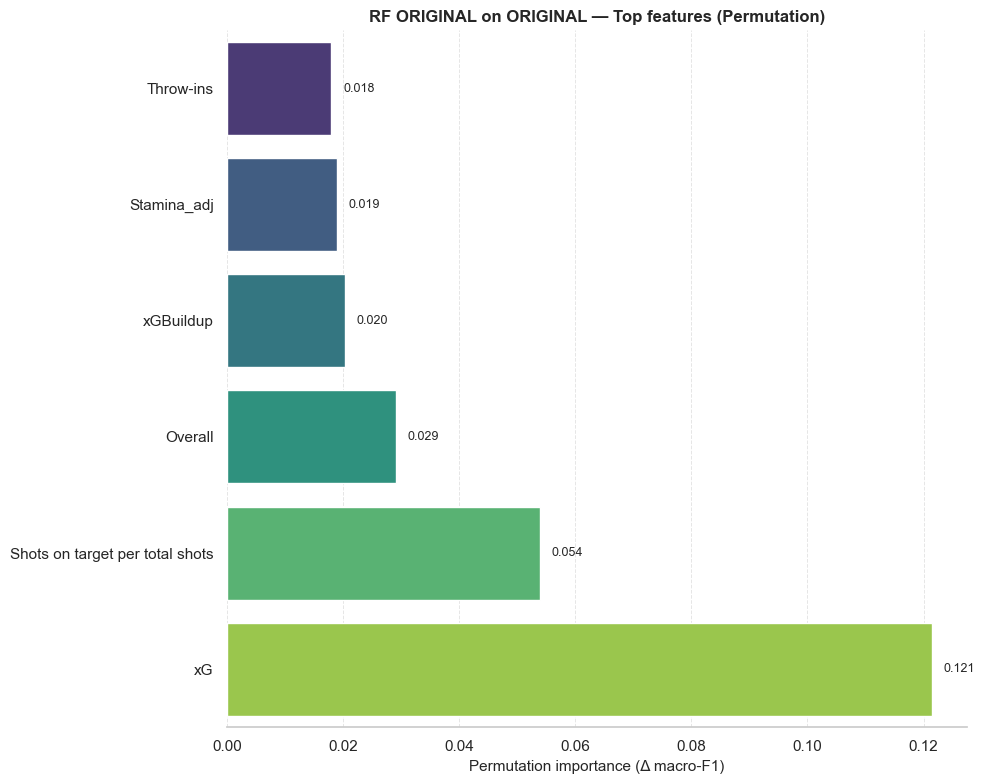


=== Feature Importance: RF AGG on AGG ===
                                          MDI    PermF1     MDI_%  PermF1r
xG_agg                               0.078424  0.090263  7.842407        1
xGBuildup_agg                        0.047273  0.024537  4.727334        2
Throw-ins_agg                        0.029169  0.021935  2.916932        3
Seasonal_Elo                         0.026973  0.016511  2.697280        4
DEEP_agg                             0.028635  0.013789  2.863489        5
Overall                              0.030621  0.009039  3.062135        6
Penalties_adj                        0.016495  0.008860  1.649465        7
key_passes_agg                       0.023057  0.008667  2.305680        8
ClubELO                              0.030195  0.008109  3.019461        9
Finishing_adj                        0.017767  0.007092  1.776702       10
Aerial duels_agg                     0.017185  0.006168  1.718505       11
Stamina_adj                          0.019070  0.005247  

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_73548/4160894052.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


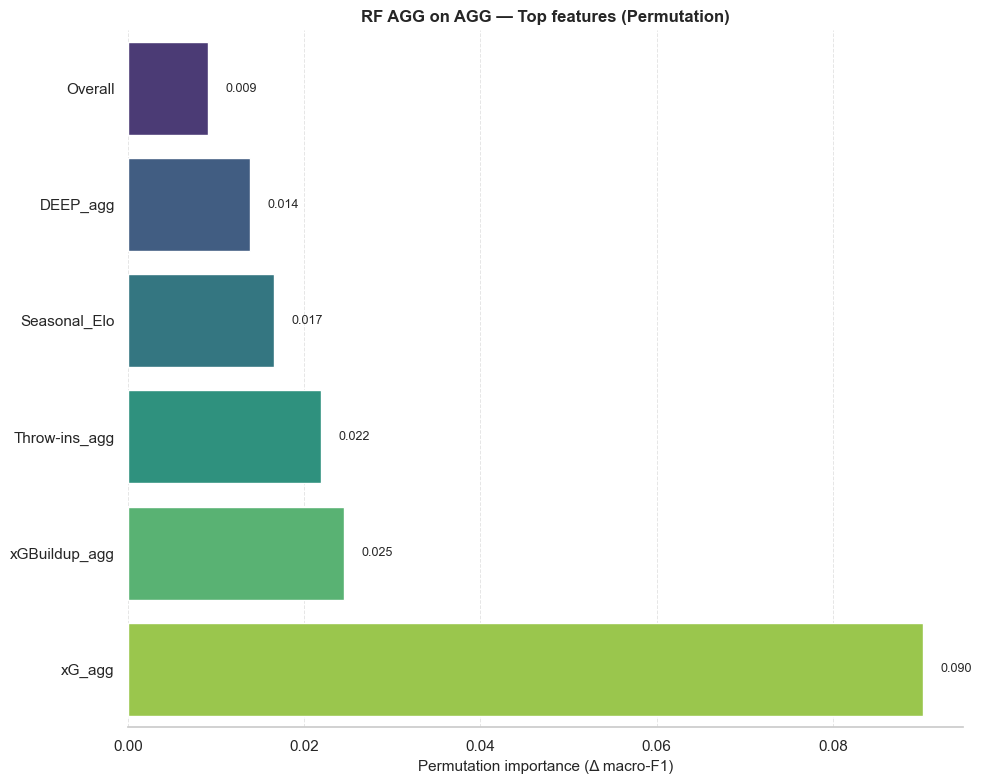


=== Feature Importance: RF WINDOW on WINDOW ===
                                         MDI    PermF1     MDI_%  PermF1r
Overall                             0.050122  0.018285  5.012197        1
DEEP_mean                           0.023520  0.013313  2.352046        2
Overall Physical_adj                0.027353  0.012236  2.735331        3
xGBuildup_median                    0.034172  0.011700  3.417210        4
ClubELO                             0.045331  0.006771  4.533149        5
key_passes_median                   0.016275  0.006705  1.627545        6
Att. Position_adj                   0.019505  0.006163  1.950491        7
Penalties_adj                       0.020509  0.005868  2.050916        8
Long Pass_adj                       0.020426  0.005548  2.042595        9
Stamina_adj                         0.027269  0.005460  2.726924       10
GK Handling_adj                     0.018364  0.004962  1.836415       11
Overall Defence_adj                 0.021041  0.004788  2.10413

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_73548/4160894052.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


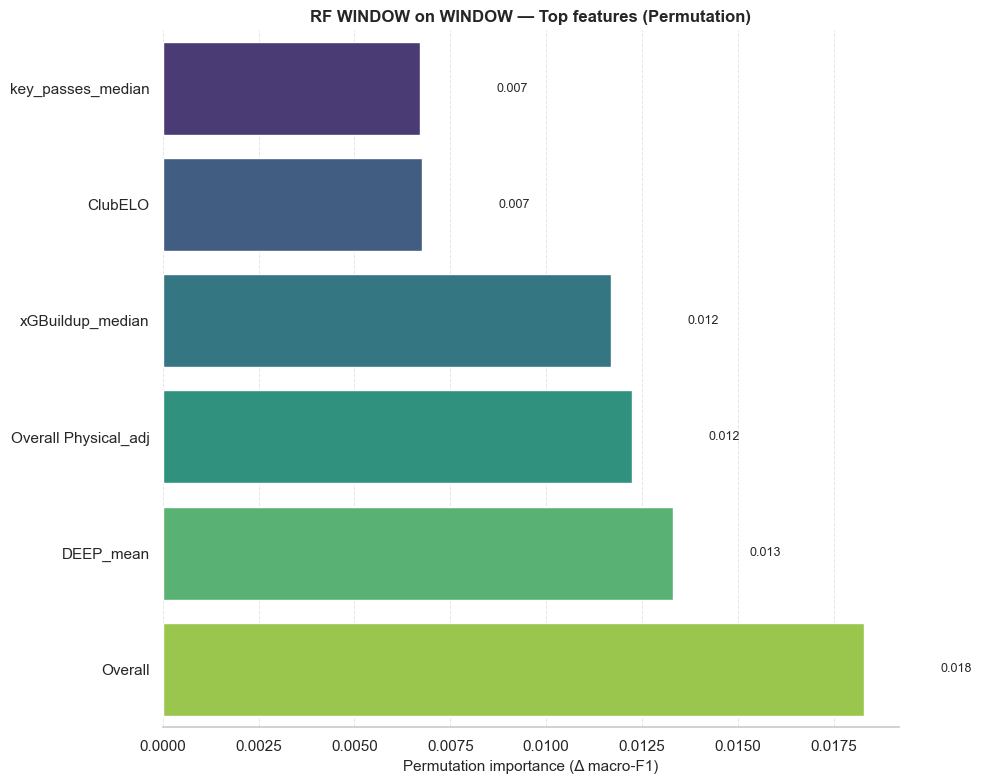


=== Feature Importance: RF ORIGINAL on AGG PROXY ===
                                   MDI    PermF1      MDI_%  PermF1r
xG                            0.108633  0.042178  10.863348        1
Long balls                    0.013887  0.002015   1.388725        2
Stamina_adj                   0.018722  0.001489   1.872173        3
Crosses                       0.012157  0.001043   1.215731        4
Tackles won                   0.012001  0.000044   1.200109        5
Overall                       0.036468  0.000002   3.646800        6
red_card                      0.001945  0.000000   0.194514        7
Dribbles                      0.012070  0.000000   1.206986        7
PPDA                          0.015406 -0.000658   1.540580        9
GK Handling_adj               0.012263 -0.000810   1.226329       10
Corner kicks                  0.012289 -0.001024   1.228886       11
Finishing_adj                 0.014524 -0.002214   1.452386       12
Att. Position_adj             0.013597 -0.002289 

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_73548/4160894052.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


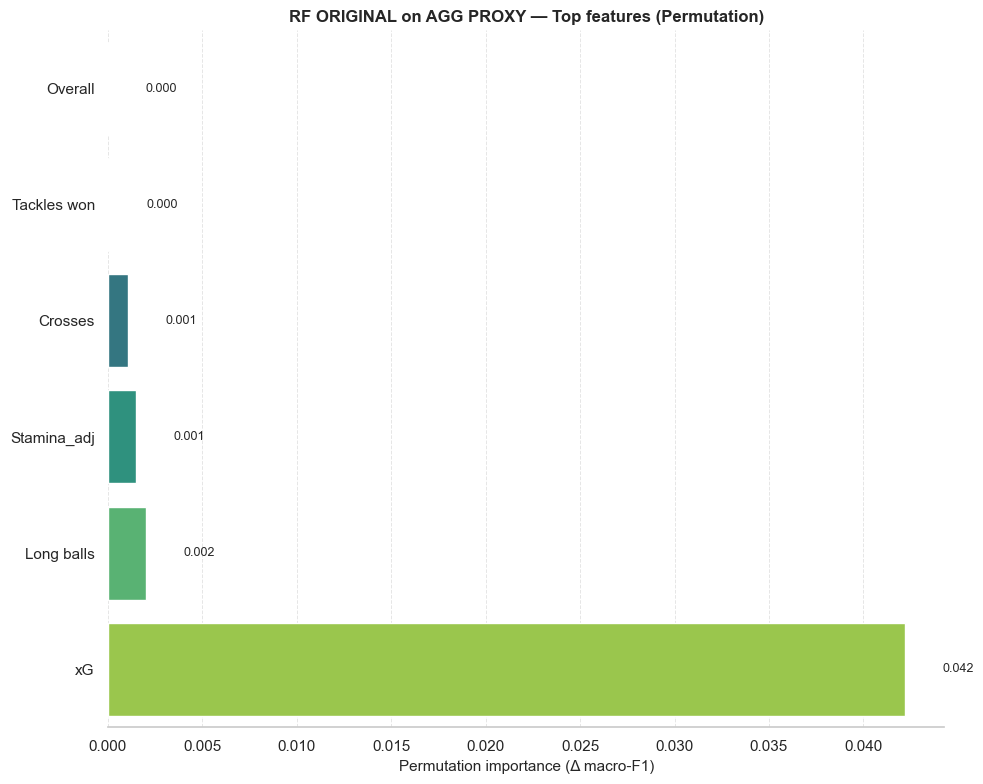


=== Feature Importance: RF ORIGINAL on WINDOW PROXY ===
                           MDI    PermF1     MDI_%  PermF1r
Overall               0.036468  0.010968  3.646800        1
Stamina_adj           0.018722  0.005683  1.872173        2
Agility_adj           0.012675  0.005462  1.267536        3
ClubELO               0.035059  0.004842  3.505873        4
FK Acc._adj           0.013523  0.004390  1.352315        5
xGBuildup             0.047401  0.004323  4.740067        6
Heading_adj           0.013747  0.004261  1.374656        7
Acceleration_adj      0.012790  0.004143  1.278958        8
GK Handling_adj       0.012263  0.003636  1.226329        9
DEEP                  0.014819  0.003467  1.481899       10
GK Kicking_adj        0.012746  0.003292  1.274641       11
Overall Shooting_adj  0.014519  0.003180  1.451942       12
Dribbling_adj         0.013919  0.002281  1.391923       13
Corner kicks          0.012289  0.002184  1.228886       14
PPDA                  0.015406  0.002118  1

/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_73548/4160894052.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


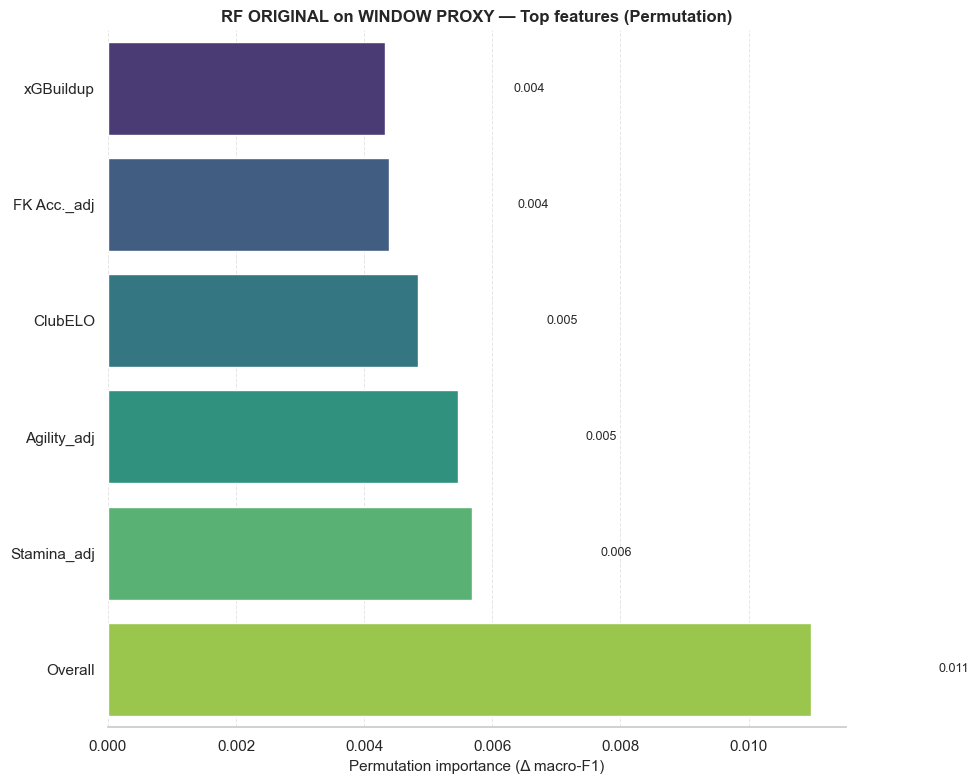

In [11]:
from sklearn.inspection import permutation_importance

def feature_importance_report(model, X_test, y_test, feature_names, title, topk=20):
    # 1) Mean Decrease in Impurity (built-in)
    mdi = pd.Series(model.feature_importances_, index=feature_names, name="MDI")

    # 2) Permutation importance (aligns with your metric)
    perm = permutation_importance(
        model, X_test, y_test,
        scoring="f1_macro",
        n_repeats=15,
        random_state=42,
        n_jobs=-1
    )
    perm_series = pd.Series(perm.importances_mean, index=feature_names, name="PermF1")

    # Combine & sort
    imp = (pd.concat([mdi, perm_series], axis=1)
             .fillna(0.0)
             .sort_values("PermF1", ascending=False))
    imp["MDI_%"]   = 100 * imp["MDI"] / (imp["MDI"].sum() or 1)
    imp["PermF1r"] = imp["PermF1"].rank(ascending=False, method="min").astype(int)

    print(f"\n=== Feature Importance: {title} ===")
    print(imp.head(topk).round(6).to_string())

    # Optional: pretty plot (top-k by permutation importance, with error bars + labels)
    top = (imp.reset_index(names="feature")
            .sort_values("PermF1", ascending=False)
            .head(6)
            .iloc[::-1])  # reverse for horizontal order (small->large bottom->top)

    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, max(4, topk * 0.4)))

    # Barplot with std error bars (if available)
    xvals = top["PermF1"].values
    ylabels = top["feature"].values
    xerr = top.get("PermF1_std", pd.Series([0]*len(top))).values  # safe if std not present

    sns.barplot(
        data=top, y="feature", x="PermF1",
        orient="h", ax=ax, errorbar=None,  # we’ll draw custom error bars
        palette="viridis"  # nice sequential palette
    )

    # Draw error bars manually so they match our precomputed std
    for i, (x, err) in enumerate(zip(xvals, xerr)):
        if err and err > 0:
            ax.errorbar(x=x, y=i, xerr=err, fmt="none", capsize=3, linewidth=1.2, alpha=0.8)

    # Value labels at end of bars
    for p in ax.patches:
        w = p.get_width()
        y = p.get_y() + p.get_height() / 2
        ax.text(w + (0.002 if w >= 0 else -0.002), y,
                f"{w:.3f}", va="center", ha="left", fontsize=9)

    ax.set_xlabel("Permutation importance (Δ macro-F1)", fontsize=11)
    ax.set_ylabel("")
    ax.set_title(title + " — Top features (Permutation)", fontsize=12, weight="bold")
    ax.grid(True, axis="x", linestyle="--", linewidth=0.7, alpha=0.5)
    sns.despine(left=True, bottom=False)
    plt.tight_layout()
    plt.show()

    return imp

# --- Run for each model with its matching test matrix ---
imp_orig = feature_importance_report(rf_orig, X_test_orig, y_test, features_train_orig,
                                     title="RF ORIGINAL on ORIGINAL", topk=20)

imp_agg  = feature_importance_report(rf_agg,  X_test_agg,  y_test, features_agg,
                                     title="RF AGG on AGG", topk=20)

imp_win  = feature_importance_report(rf_win,  X_test_win,  y_test, features_win,
                                     title="RF WINDOW on WINDOW", topk=20)
# --- Also: AGG data on ORIGINAL model (proxy) ---
imp_agg_on_orig = feature_importance_report(
    rf_orig,
    X_test_agg_proxy,            # proxy matrix with original feature names
    y_test,
    features_train_orig,         # keep ORIGINAL names to align with the model
    title="RF ORIGINAL on AGG PROXY",
    topk=20
)

# --- Also: WINDOW data on ORIGINAL model (proxy) ---
imp_win_on_orig = feature_importance_report(
    rf_orig,
    X_test_win_proxy,            # proxy matrix with original feature names
    y_test,
    features_train_orig,         # keep ORIGINAL names to align with the model
    title="RF ORIGINAL on WINDOW PROXY",
    topk=20
)

In [12]:
# picking the top-10 features by permutation importance for each model
top10_orig        = imp_orig.sort_values("PermF1", ascending=False).head(10).index.tolist()
top10_agg         = imp_agg.sort_values("PermF1", ascending=False).head(10).index.tolist()
top10_win         = imp_win.sort_values("PermF1", ascending=False).head(10).index.tolist()
top10_agg_on_orig = imp_agg_on_orig.sort_values("PermF1", ascending=False).head(10).index.tolist()
top10_win_on_orig = imp_win_on_orig.sort_values("PermF1", ascending=False).head(10).index.tolist()
# !!!
# Sanity check: print the top-10 features for each model
print("Top10 — ORIGINAL:", top10_orig)
print("Top10 — AGG:", top10_agg)
print("Top10 — WINDOW:", top10_win)
print("Top10 — ORIGINAL on AGG PROXY:", top10_agg_on_orig)
print("Top10 — ORIGINAL on WINDOW PROXY:", top10_win_on_orig)

# --- Build proxy TRAIN matrices (you already have test proxies) ---
X_train_agg_proxy = make_proxy_X(train_df, features_train_orig, agg_proxy_map)


X_train_win_proxy = make_proxy_X(train_df, features_train_orig, win_proxy_map)


# --- Slice to top-10 for each scenario ---
# ORIGINAL
Xtr_orig10 = X_train_orig[top10_orig]
Xte_orig10 = X_test_orig[top10_orig]

# AGG
Xtr_agg10 = X_train_agg[top10_agg]
Xte_agg10 = X_test_agg[top10_agg]

# WINDOW
Xtr_win10 = X_train_win[top10_win]
Xte_win10 = X_test_win[top10_win]

# ORIGINAL on AGG PROXY  (note: names are ORIGINAL, data comes from proxy matrices)
Xtr_aggproxy10 = X_train_agg_proxy[top10_agg_on_orig]
Xte_aggproxy10 = X_test_agg_proxy[top10_agg_on_orig]

# ORIGINAL on WINDOW PROXY
Xtr_winproxy10 = X_train_win_proxy[top10_win_on_orig]
Xte_winproxy10 = X_test_win_proxy[top10_win_on_orig]

# --- Retrain & evaluate ---
results = []

def train_eval(name, Xtr, Xte):
    mdl = fit_rf(Xtr, y_train)
    evaluate(mdl, Xte, y_test, title=f"RF [{name}] (Top-10)")
    y_pred = mdl.predict(Xte)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro-F1": f1_score(y_test, y_pred, average='macro'),
        "Top10": list(Xtr.columns)
    })
    return mdl

rf_orig_top10        = train_eval("ORIGINAL on ORIGINAL", Xtr_orig10, Xte_orig10)
rf_agg_top10         = train_eval("AGG on AGG", Xtr_agg10, Xte_agg10)
rf_win_top10         = train_eval("WINDOW on WINDOW", Xtr_win10, Xte_win10)
rf_aggproxy_top10    = train_eval("ORIGINAL on AGG PROXY", Xtr_aggproxy10, Xte_aggproxy10)
rf_winproxy_top10    = train_eval("ORIGINAL on WINDOW PROXY", Xtr_winproxy10, Xte_winproxy10)

# Compact comparison table
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("\n=== Comparison (Top-10 feature models) ===")
print(results_df[["Model", "Accuracy", "Macro-F1"]].round(4).to_string(index=False))

# pd.set_option('display.max_colwidth', None)
# display(results_df)


Top10 — ORIGINAL: ['xG', 'Shots on target per total shots', 'Overall', 'xGBuildup', 'Stamina_adj', 'Throw-ins', 'Overall Physical_adj', 'Crosses', 'ClubELO', 'key_passes']
Top10 — AGG: ['xG_agg', 'xGBuildup_agg', 'Throw-ins_agg', 'Seasonal_Elo', 'DEEP_agg', 'Overall', 'Penalties_adj', 'key_passes_agg', 'ClubELO', 'Finishing_adj']
Top10 — WINDOW: ['Overall', 'DEEP_mean', 'Overall Physical_adj', 'xGBuildup_median', 'ClubELO', 'key_passes_median', 'Att. Position_adj', 'Penalties_adj', 'Long Pass_adj', 'Stamina_adj']
Top10 — ORIGINAL on AGG PROXY: ['xG', 'Long balls', 'Stamina_adj', 'Crosses', 'Tackles won', 'Overall', 'red_card', 'Dribbles', 'PPDA', 'GK Handling_adj']
Top10 — ORIGINAL on WINDOW PROXY: ['Overall', 'Stamina_adj', 'Agility_adj', 'ClubELO', 'FK Acc._adj', 'xGBuildup', 'Heading_adj', 'Acceleration_adj', 'GK Handling_adj', 'DEEP']



=== RF [ORIGINAL on ORIGINAL] (Top-10) ===
Accuracy: 0.6550 | Macro-F1: 0.5882
              precision    recall  f1-score   support

           W       0.74      0.82      0.78       323
           D       0.34      0.29      0.31       147
           L       0.70      0.65      0.67       214

    accuracy                           0.65       684
   macro avg       0.59      0.59      0.59       684
weighted avg       0.64      0.65      0.65       684

Confusion Matrix [rows:true, cols:pred]:
     W   D    L
W  266  38   19
D   63  42   42
L   32  42  140

=== RF [AGG on AGG] (Top-10) ===
Accuracy: 0.6550 | Macro-F1: 0.5652
              precision    recall  f1-score   support

           W       0.74      0.83      0.78       323
           D       0.35      0.19      0.25       147
           L       0.63      0.71      0.67       214

    accuracy                           0.65       684
   macro avg       0.57      0.58      0.57       684
weighted avg       0.62      0.65     

In [13]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Fixed, stable mapping using your label_order
le = LabelEncoder()
le.fit(label_order)  # ensures W/D/L map stays consistent

def fit_xgb(X, y_str):
    # Encode string labels -> ints for XGBoost
    y_enc = le.transform(y_str)
    model = XGBClassifier(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softmax",
        num_class=len(label_order),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
    model.fit(X, y_enc)
    return model

def evaluate_xgb(model, X, y_true_str, title=""):
    # Predict ints -> back to strings
    y_pred_enc = model.predict(X)
    y_pred_str = le.inverse_transform(y_pred_enc.astype(int))

    acc = accuracy_score(y_true_str, y_pred_str)
    f1m = f1_score(y_true_str, y_pred_str, average='macro')
    print(f"\n=== {title} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}")
    print(classification_report(y_true_str, y_pred_str, labels=label_order, zero_division=0))
    cm = confusion_matrix(y_true_str, y_pred_str, labels=label_order)
    print("Confusion Matrix [rows:true, cols:pred]:")
    print(pd.DataFrame(cm, index=label_order, columns=label_order))
    return y_pred_str, acc, f1m

def train_eval_xgb(name, Xtr, Xte):
    mdl = fit_xgb(Xtr, y_train)
    y_pred, acc, f1m = evaluate_xgb(mdl, Xte, y_test, title=f"XGB [{name}] (Top-10)")
    results.append({
        "Model": f"XGB {name}",
        "Accuracy": acc,
        "Macro-F1": f1m,
        "Top10": list(Xtr.columns)
    })
    return mdl

# ORIGINAL
train_eval_xgb("ORIGINAL on ORIGINAL", Xtr_orig10, Xte_orig10)

# AGG
train_eval_xgb("AGG on AGG", Xtr_agg10, Xte_agg10)

# WINDOW
train_eval_xgb("WINDOW on WINDOW", Xtr_win10, Xte_win10)

# AGG PROXY
train_eval_xgb("ORIGINAL on AGG PROXY", Xtr_aggproxy10, Xte_aggproxy10)

# WINDOW PROXY
train_eval_xgb("ORIGINAL on WINDOW PROXY", Xtr_winproxy10, Xte_winproxy10)

# Optional: updated comparison table print
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("\n=== Comparison (incl. XGB on Top-10 features) ===")
print(results_df[["Model", "Accuracy", "Macro-F1"]].round(4).to_string(index=False))



=== XGB [ORIGINAL on ORIGINAL] (Top-10) ===
Accuracy: 0.6535 | Macro-F1: 0.5903
              precision    recall  f1-score   support

           W       0.72      0.82      0.77       323
           D       0.39      0.31      0.34       147
           L       0.68      0.64      0.66       214

    accuracy                           0.65       684
   macro avg       0.60      0.59      0.59       684
weighted avg       0.64      0.65      0.64       684

Confusion Matrix [rows:true, cols:pred]:
     W   D    L
W  265  36   22
D   60  45   42
L   43  34  137

=== XGB [AGG on AGG] (Top-10) ===
Accuracy: 0.6520 | Macro-F1: 0.5683
              precision    recall  f1-score   support

           W       0.73      0.82      0.77       323
           D       0.33      0.20      0.25       147
           L       0.66      0.71      0.68       214

    accuracy                           0.65       684
   macro avg       0.57      0.58      0.57       684
weighted avg       0.62      0.65   

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import Input
import tensorflow as tf
tf.random.set_seed(42)

# Ensure we have a stable label encoder consistent with label_order
if "le" not in globals():
    le = LabelEncoder()
    le.fit(label_order)

def fit_nn(X, y_str):
    # Encode labels
    y_enc = le.transform(y_str)

    # Class weights (help draws)
    cw = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(len(label_order)),
        y=y_enc
    )
    class_weight = {i: w for i, w in enumerate(cw)}

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Simple MLP
    model = Sequential([
    Input(shape=(X.shape[1],)),   # preferred way
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(len(label_order), activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

    es = EarlyStopping(monitor="val_loss", patience=12,
                       restore_best_weights=True, verbose=0)

    model.fit(
        X_scaled, y_enc,
        epochs=200,
        batch_size=64,
        validation_split=0.2,
        callbacks=[es],
        verbose=0,
        class_weight=class_weight
    )
    return model, scaler

def evaluate_nn(model, scaler, X, y_true_str, title=""):
    X_scaled = scaler.transform(X)
    y_pred_proba = model.predict(X_scaled, verbose=0)
    y_pred_enc = y_pred_proba.argmax(axis=1)
    y_pred_str = le.inverse_transform(y_pred_enc)

    acc = accuracy_score(y_true_str, y_pred_str)
    f1m = f1_score(y_true_str, y_pred_str, average='macro')
    print(f"\n=== {title} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}")
    print(classification_report(y_true_str, y_pred_str, labels=label_order, zero_division=0))
    cm = confusion_matrix(y_true_str, y_pred_str, labels=label_order)
    print("Confusion Matrix [rows:true, cols:pred]:")
    print(pd.DataFrame(cm, index=label_order, columns=label_order))
    return acc, f1m

def train_eval_nn(name, Xtr, Xte):
    mdl, scaler = fit_nn(Xtr, y_train)
    acc, f1m = evaluate_nn(mdl, scaler, Xte, y_test, title=f"NN [{name}] (Top-10)")
    results.append({
        "Model": f"NN {name}",
        "Accuracy": acc,
        "Macro-F1": f1m,
        "Top10": list(Xtr.columns)
    })
    return mdl, scaler

# ORIGINAL
nn_orig, sc_orig = train_eval_nn("ORIGINAL on ORIGINAL", Xtr_orig10, Xte_orig10)

# AGG
nn_agg, sc_agg = train_eval_nn("AGG on AGG", Xtr_agg10, Xte_agg10)

# WINDOW
nn_win, sc_win = train_eval_nn("WINDOW on WINDOW", Xtr_win10, Xte_win10)

# AGG PROXY
nn_aggproxy, sc_aggproxy = train_eval_nn("ORIGINAL on AGG PROXY", Xtr_aggproxy10, Xte_aggproxy10)

# WINDOW PROXY
nn_winproxy, sc_winproxy = train_eval_nn("ORIGINAL on WINDOW PROXY", Xtr_winproxy10, Xte_winproxy10)

# Updated comparison table
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("\n=== Comparison (RF, XGB, NN on Top-10 features) ===")
print(results_df[["Model", "Accuracy", "Macro-F1"]].round(4).to_string(index=False))



=== NN [ORIGINAL on ORIGINAL] (Top-10) ===
Accuracy: 0.6374 | Macro-F1: 0.5997
              precision    recall  f1-score   support

           W       0.80      0.71      0.75       323
           D       0.33      0.40      0.36       147
           L       0.68      0.70      0.69       214

    accuracy                           0.64       684
   macro avg       0.60      0.60      0.60       684
weighted avg       0.66      0.64      0.65       684

Confusion Matrix [rows:true, cols:pred]:
     W   D    L
W  228  73   22
D   40  59   48
L   17  48  149

=== NN [AGG on AGG] (Top-10) ===
Accuracy: 0.6564 | Macro-F1: 0.6070
              precision    recall  f1-score   support

           W       0.77      0.76      0.77       323
           D       0.36      0.36      0.36       147
           L       0.69      0.70      0.69       214

    accuracy                           0.66       684
   macro avg       0.61      0.61      0.61       684
weighted avg       0.66      0.66     

In [15]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

# Ensure stable label encoding consistent with label_order
if "le" not in globals():
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    le.fit(label_order)


from tensorflow.keras import Input
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
import tensorflow as tf

def build_nn(input_dim, n_hidden=2, units=64, dropout=0.3, l2reg=0.0, lr=1e-3):
    model = Sequential()
    model.add(Input(shape=(input_dim,), dtype="float32"))  # preferred API (also removes the warning)

    # first hidden
    model.add(Dense(units, activation="relu",
                    kernel_initializer="he_normal",
                    kernel_regularizer=regularizers.l2(l2reg)))
    if dropout and dropout > 0:
        model.add(Dropout(dropout))

    # remaining hidden layers
    for _ in range(n_hidden - 1):
        model.add(Dense(units, activation="relu",
                        kernel_initializer="he_normal",
                        kernel_regularizer=regularizers.l2(l2reg)))
        if dropout and dropout > 0:
            model.add(Dropout(dropout))

    # output
    model.add(Dense(len(label_order), activation="softmax"))

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def tune_nn_random_search(
    X_train, y_train_str,
    n_iter=20,
    n_splits=3,
    max_epochs=200,
    patience=12,
    seed=42,
):
    rng = np.random.default_rng(seed)
    y_enc = le.transform(y_train_str)

    # Search space
    space = {
        "n_hidden":    [1, 2, 3],
        "units":       [32, 64, 96, 128],
        "dropout":     [0.0, 0.2, 0.3, 0.4],
        "l2reg":       [0.0, 1e-5, 1e-4, 5e-4, 1e-3],
        "lr":          [5e-4, 1e-3, 2e-3, 5e-3],
        "batch_size":  [32, 64, 128],
    }

    def sample_params():
        return {
            k: rng.choice(v) for k, v in space.items()
        }

    tscv = TimeSeriesSplit(n_splits=n_splits)
    best = {"score": -np.inf, "params": None}

    for it in range(1, n_iter+1):
        params = sample_params()

        fold_scores = []
        for tr_idx, va_idx in tscv.split(X_train):
            X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
            y_tr, y_va = y_enc[tr_idx], y_enc[va_idx]

            # Scale on each fold to avoid leakage
            scaler = StandardScaler()
            X_trs = scaler.fit_transform(X_tr)
            X_vas = scaler.transform(X_va)

            # Class weights per fold
            cw = compute_class_weight("balanced", classes=np.arange(len(label_order)), y=y_tr)
            class_weight = {i: w for i, w in enumerate(cw)}

            model = build_nn(
                input_dim=X_tr.shape[1],
                n_hidden=params["n_hidden"],
                units=params["units"],
                dropout=params["dropout"],
                l2reg=params["l2reg"],
                lr=params["lr"],
            )

            es = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)

            model.fit(
                X_trs, y_tr,
                epochs=max_epochs,
                batch_size=params["batch_size"],
                validation_data=(X_vas, y_va),
                callbacks=[es],
                verbose=0,
                class_weight=class_weight
            )

            y_va_pred = model.predict(X_vas, verbose=0).argmax(axis=1)
            f1m = f1_score(y_va, y_va_pred, average="macro")
            fold_scores.append(f1m)

        mean_f1 = float(np.mean(fold_scores))
        if mean_f1 > best["score"]:
            best = {"score": mean_f1, "params": params}

        print(f"[{it:02d}/{n_iter}] F1_macro={mean_f1:.4f} params={params}")

    print("\nBest (CV) F1_macro:", round(best["score"], 4))
    print("Best params:", best["params"])

    # ---- Refit best model on FULL training set ----
    # Scale on full train
    scaler = StandardScaler()
    X_trs_full = scaler.fit_transform(X_train)

    # Class weights on full train
    cw_full = compute_class_weight("balanced", classes=np.arange(len(label_order)), y=le.transform(y_train_str))
    class_weight_full = {i: w for i, w in enumerate(cw_full)}

    best_model = build_nn(
        input_dim=X_train.shape[1],
        n_hidden=best["params"]["n_hidden"],
        units=best["params"]["units"],
        dropout=best["params"]["dropout"],
        l2reg=best["params"]["l2reg"],
        lr=best["params"]["lr"],
    )
    es_full = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)
    best_model.fit(
        X_trs_full, le.transform(y_train_str),
        epochs=max_epochs,
        batch_size=best["params"]["batch_size"],
        validation_split=0.15,  # small holdout inside train just to keep early stopping sensible
        callbacks=[es_full],
        verbose=0,
        class_weight=class_weight_full
    )

    return best_model, scaler, best

def evaluate_nn_model(model, scaler, X_test, y_test_str, title=""):
    Xs = scaler.transform(X_test)
    y_pred_enc = model.predict(Xs, verbose=0).argmax(axis=1)
    y_pred_str = le.inverse_transform(y_pred_enc)
    acc = accuracy_score(y_test_str, y_pred_str)
    f1m = f1_score(y_test_str, y_pred_str, average="macro")
    print(f"\n=== {title} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}")
    print(classification_report(y_test_str, y_pred_str, labels=label_order, zero_division=0))
    cm = confusion_matrix(y_test_str, y_pred_str, labels=label_order)
    print("Confusion Matrix [rows:true, cols:pred]:")
    print(pd.DataFrame(cm, index=label_order, columns=label_order))
    return acc, f1m, y_pred_str


In [16]:
# Tune on training set only (time-aware CV), then refit & evaluate on test
best_nn_agg, scaler_agg, best_info_agg = tune_nn_random_search(
    Xtr_agg10, y_train,
    n_iter=25,        # bump up for a deeper search
    n_splits=3,       # more splits = slower but stabler
    max_epochs=200,
    patience=15,
    seed=42
)

acc, f1m, _ = evaluate_nn_model(best_nn_agg, scaler_agg, Xte_agg10, y_test, title="NN [AGG on AGG] — Tuned")
results.append({"Model": "NN AGG on AGG (tuned)", "Accuracy": acc, "Macro-F1": f1m, "Top10": list(Xtr_agg10.columns)})

# Optional: compare table
results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
print("\n=== Comparison (with tuned NN) ===")
print(results_df[["Model", "Accuracy", "Macro-F1"]].round(4).to_string(index=False))

print("\nBest NN params (AGG):", best_info_agg["params"])


[01/25] F1_macro=0.6009 params={'n_hidden': 1, 'units': 128, 'dropout': 0.3, 'l2reg': 0.0001, 'lr': 0.001, 'batch_size': 128}
[02/25] F1_macro=0.6018 params={'n_hidden': 1, 'units': 96, 'dropout': 0.0, 'l2reg': 0.0, 'lr': 0.002, 'batch_size': 128}
[03/25] F1_macro=0.6165 params={'n_hidden': 3, 'units': 128, 'dropout': 0.3, 'l2reg': 0.0005, 'lr': 0.002, 'batch_size': 32}
[04/25] F1_macro=0.5671 params={'n_hidden': 3, 'units': 64, 'dropout': 0.3, 'l2reg': 1e-05, 'lr': 0.0005, 'batch_size': 128}
[05/25] F1_macro=0.6085 params={'n_hidden': 3, 'units': 96, 'dropout': 0.2, 'l2reg': 0.001, 'lr': 0.002, 'batch_size': 64}
[06/25] F1_macro=0.5890 params={'n_hidden': 2, 'units': 32, 'dropout': 0.0, 'l2reg': 0.0001, 'lr': 0.005, 'batch_size': 32}
[07/25] F1_macro=0.5918 params={'n_hidden': 3, 'units': 128, 'dropout': 0.2, 'l2reg': 0.0005, 'lr': 0.0005, 'batch_size': 128}
[08/25] F1_macro=0.5790 params={'n_hidden': 3, 'units': 64, 'dropout': 0.0, 'l2reg': 0.001, 'lr': 0.001, 'batch_size': 128}
[09/

In [17]:
from sklearn.utils.class_weight import compute_class_weight

# --- helper: make class weights with draw multiplier ---
def make_class_weights(y_enc, draw_mult=1.0, target_label='D'):
    base_cw = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(len(label_order)),
        y=y_enc
    ).astype(float)
    # index of 'D' per your fixed label_order / encoder
    d_idx = le.transform([target_label])[0]
    base_cw[d_idx] *= float(draw_mult)
    return {i: w for i, w in enumerate(base_cw)}

def tune_nn_random_search(
    X_train, y_train_str,
    n_iter=20,
    n_splits=3,
    max_epochs=200,
    patience=12,
    seed=42,
):
    rng = np.random.default_rng(seed)
    y_enc_full = le.transform(y_train_str)

    # --- extended search space (added draw_mult) ---
    space = {
        "n_hidden":    [1, 2, 3],
        "units":       [32, 64, 96, 128],
        "dropout":     [0.0, 0.2, 0.3, 0.4],
        "l2reg":       [0.0, 1e-5, 1e-4, 5e-4, 1e-3],
        "lr":          [5e-4, 1e-3, 2e-3, 5e-3],
        "batch_size":  [32, 64, 128],
        "draw_mult":   [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0],  # NEW
    }

    def sample_params():
        return {k: rng.choice(v) for k, v in space.items()}

    tscv = TimeSeriesSplit(n_splits=n_splits)
    best = {"score": -np.inf, "params": None}

    for it in range(1, n_iter+1):
        params = sample_params()

        fold_scores = []
        for tr_idx, va_idx in tscv.split(X_train):
            X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
            y_tr, y_va = y_enc_full[tr_idx], y_enc_full[va_idx]

            # Scale per fold (no leakage)
            scaler = StandardScaler()
            X_trs = scaler.fit_transform(X_tr)
            X_vas = scaler.transform(X_va)

            # --- class weights with draw multiplier ---
            class_weight = make_class_weights(y_tr, draw_mult=params["draw_mult"], target_label='D')

            model = build_nn(
                input_dim=X_tr.shape[1],
                n_hidden=params["n_hidden"],
                units=params["units"],
                dropout=params["dropout"],
                l2reg=params["l2reg"],
                lr=params["lr"],
            )
            es = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)

            model.fit(
                X_trs, y_tr,
                epochs=max_epochs,
                batch_size=params["batch_size"],
                validation_data=(X_vas, y_va),
                callbacks=[es],
                verbose=0,
                class_weight=class_weight
            )

            y_va_pred = model.predict(X_vas, verbose=0).argmax(axis=1)
            f1m = f1_score(y_va, y_va_pred, average="macro")
            fold_scores.append(f1m)

        mean_f1 = float(np.mean(fold_scores))
        if mean_f1 > best["score"]:
            best = {"score": mean_f1, "params": params}

        print(f"[{it:02d}/{n_iter}] F1_macro={mean_f1:.4f} params={params}")

    print("\nBest (CV) F1_macro:", round(best["score"], 4))
    print("Best params:", best["params"])

    # ---- Refit best model on FULL training set ----
    scaler = StandardScaler()
    X_trs_full = scaler.fit_transform(X_train)

    # class weights on full train with best draw_mult
    class_weight_full = make_class_weights(
        y_enc_full,
        draw_mult=best["params"]["draw_mult"],
        target_label='D'
    )

    best_model = build_nn(
        input_dim=X_train.shape[1],
        n_hidden=best["params"]["n_hidden"],
        units=best["params"]["units"],
        dropout=best["params"]["dropout"],
        l2reg=best["params"]["l2reg"],
        lr=best["params"]["lr"],
    )
    es_full = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)
    best_model.fit(
        X_trs_full, y_enc_full,
        epochs=max_epochs,
        batch_size=best["params"]["batch_size"],
        validation_split=0.15,
        callbacks=[es_full],
        verbose=0,
        class_weight=class_weight_full
    )

    return best_model, scaler, best


In [18]:
best_nn_agg, scaler_agg, best_info_agg = tune_nn_random_search(
    Xtr_agg10, y_train,
    n_iter=35,   # feel free to increase
    n_splits=3,
    max_epochs=220,
    patience=18,
    seed=42
)

acc, f1m, _ = evaluate_nn_model(best_nn_agg, scaler_agg, Xte_agg10, y_test,
                                title="NN [AGG on AGG] — Tuned (Draw-weight search)")
results.append({"Model": "NN AGG on AGG (tuned+draw_mult)", "Accuracy": acc, "Macro-F1": f1m, "Top10": list(Xtr_agg10.columns)})
print("\nBest params incl. draw_mult:", best_info_agg["params"])


[01/35] F1_macro=0.6096 params={'n_hidden': 1, 'units': 128, 'dropout': 0.3, 'l2reg': 0.0001, 'lr': 0.001, 'batch_size': 128, 'draw_mult': 1.0}
[02/35] F1_macro=0.5252 params={'n_hidden': 3, 'units': 32, 'dropout': 0.0, 'l2reg': 0.0001, 'lr': 0.005, 'batch_size': 128, 'draw_mult': 2.5}
[03/35] F1_macro=0.5677 params={'n_hidden': 3, 'units': 128, 'dropout': 0.3, 'l2reg': 0.0, 'lr': 0.005, 'batch_size': 64, 'draw_mult': 2.0}
[04/35] F1_macro=0.4827 params={'n_hidden': 2, 'units': 32, 'dropout': 0.4, 'l2reg': 0.0005, 'lr': 0.002, 'batch_size': 64, 'draw_mult': 2.5}
[05/35] F1_macro=0.4621 params={'n_hidden': 2, 'units': 64, 'dropout': 0.2, 'l2reg': 1e-05, 'lr': 0.0005, 'batch_size': 64, 'draw_mult': 3.0}
[06/35] F1_macro=0.5463 params={'n_hidden': 1, 'units': 128, 'dropout': 0.4, 'l2reg': 1e-05, 'lr': 0.002, 'batch_size': 32, 'draw_mult': 2.5}
[07/35] F1_macro=0.5583 params={'n_hidden': 3, 'units': 64, 'dropout': 0.0, 'l2reg': 0.001, 'lr': 0.001, 'batch_size': 128, 'draw_mult': 2.25}
[08/

In [19]:


# ---------- Class-weight helpers ----------
def make_class_weights(y_enc, draw_mult=1.0, target_label='D'):
    base = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(len(label_order)),
        y=y_enc
    ).astype(float)
    d_idx = le.transform([target_label])[0]
    base[d_idx] *= float(draw_mult)
    # return both dict (for CE) and vector (for focal)
    cw_dict = {i: w for i, w in enumerate(base)}
    return cw_dict, base  # (dict, vector)

# ---------- Multiclass focal loss with per-class alpha ----------
def focal_loss_fn(num_classes, alpha_vec, gamma=2.0):
    alpha = tf.constant(alpha_vec, dtype=tf.float32)  # shape [C]

    def loss(y_true, y_pred):
        # y_true: int labels, shape [N]
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)  # avoid log(0)

        # one-hot
        y_true_oh = tf.one_hot(y_true, depth=num_classes, dtype=tf.float32)  # [N, C]

        # p_t = y_pred for the true class
        p_t = tf.reduce_sum(y_true_oh * y_pred, axis=-1)  # [N]

        # alpha_t = alpha for the true class
        alpha_t = tf.gather(alpha, y_true)  # [N]

        # focal loss
        focal = -alpha_t * tf.pow(1.0 - p_t, gamma) * tf.math.log(p_t)
        return tf.reduce_mean(focal)

    return loss

# ---------- NN builder (no loss baked in) ----------
def build_nn_core(input_dim, n_hidden=2, units=64, dropout=0.3, l2reg=0.0, lr=1e-3):
    model = Sequential()
    model.add(Dense(units, activation="relu",
                    kernel_regularizer=regularizers.l2(l2reg),
                    input_shape=(input_dim,)))
    if dropout > 0:
        model.add(Dropout(dropout))
    for _ in range(n_hidden-1):
        model.add(Dense(units, activation="relu",
                        kernel_regularizer=regularizers.l2(l2reg)))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(len(label_order), activation="softmax"))
    opt = tf.keras.optimizers.Adam(learning_rate=lr)
    return model, opt

# ---------- Tuner with loss_type + gamma ----------
def tune_nn_random_search(
    X_train, y_train_str,
    n_iter=30,
    n_splits=3,
    max_epochs=200,
    patience=15,
    seed=42,
):
    rng = np.random.default_rng(seed)
    y_enc_full = le.transform(y_train_str)

    space = {
        "n_hidden":    [1, 2, 3],
        "units":       [32, 64, 96, 128],
        "dropout":     [0.0, 0.2, 0.3, 0.4],
        "l2reg":       [0.0, 1e-5, 1e-4, 5e-4, 1e-3],
        "lr":          [5e-4, 1e-3, 2e-3, 5e-3],
        "batch_size":  [32, 64, 128],
        "draw_mult":   [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0],
        "loss_type":   ["ce", "focal"],
        "gamma":       [1.0, 1.5, 2.0, 2.5],
    }

    def sample_params():
        return {k: rng.choice(v) for k, v in space.items()}

    tscv = TimeSeriesSplit(n_splits=n_splits)
    best = {"score": -np.inf, "params": None}

    for it in range(1, n_iter+1):
        params = sample_params()

        fold_scores = []
        for tr_idx, va_idx in tscv.split(X_train):
            tf.keras.backend.clear_session()

            X_tr, X_va = X_train.iloc[tr_idx].astype("float32"), X_train.iloc[va_idx].astype("float32")
            y_tr, y_va = y_enc_full[tr_idx], y_enc_full[va_idx]

            scaler = StandardScaler()
            X_trs = scaler.fit_transform(X_tr)
            X_vas = scaler.transform(X_va)

            # --- per-fold class weights (dict for CE, vector for focal alpha) ---
            cw_dict, cw_vec = make_class_weights(y_tr, draw_mult=params["draw_mult"], target_label='D')

            model = build_nn(
                input_dim=X_tr.shape[1],
                n_hidden=params["n_hidden"],
                units=params["units"],
                dropout=params["dropout"],
                l2reg=params["l2reg"],
                lr=params["lr"],
            )

            # Compile for chosen loss
            if params["loss_type"] == "focal":
                loss = focal_loss_fn(num_classes=len(label_order), alpha_vec=cw_vec, gamma=params["gamma"])
                model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=params["lr"]),
                              loss=loss, metrics=["accuracy"])
                fit_kwargs = {"class_weight": None}  # alpha handled by loss
            else:  # cross-entropy
                model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=params["lr"]),
                              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
                fit_kwargs = {"class_weight": cw_dict}

            es = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)

            model.fit(
                X_trs, y_tr,
                epochs=max_epochs,
                batch_size=params["batch_size"],
                validation_data=(X_vas, y_va),
                callbacks=[es],
                verbose=0,
                shuffle=False,
                **fit_kwargs
            )

            y_va_pred = model.predict(X_vas, verbose=0).argmax(axis=1)
            f1m = f1_score(y_va, y_va_pred, average="macro")
            fold_scores.append(f1m)

        mean_f1 = float(np.mean(fold_scores))
        if mean_f1 > best["score"]:
            best = {"score": mean_f1, "params": params}

        print(f"[{it:02d}/{n_iter}] F1_macro={mean_f1:.4f} params={params}")

    print("\nBest (CV) F1_macro:", round(best["score"], 4))
    print("Best params:", best["params"])

    # ---- Refit best model on FULL training set (time-aware) ----
    tf.keras.backend.clear_session()

    scaler = StandardScaler()
    X_trs_full = scaler.fit_transform(X_train.astype("float32"))

    y_enc_full = le.transform(y_train_str)
    cw_dict_full, cw_vec_full = make_class_weights(
        y_enc_full, draw_mult=best["params"]["draw_mult"], target_label='D'
    )

    best_model = build_nn(
        input_dim=X_train.shape[1],
        n_hidden=best["params"]["n_hidden"],
        units=best["params"]["units"],
        dropout=best["params"]["dropout"],
        l2reg=best["params"]["l2reg"],
        lr=best["params"]["lr"],
    )

    # Compile with the best loss
    if best["params"]["loss_type"] == "focal":
        loss = focal_loss_fn(num_classes=len(label_order), alpha_vec=cw_vec_full, gamma=best["params"]["gamma"])
        best_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=best["params"]["lr"]),
                           loss=loss, metrics=["accuracy"])
        final_fit_kwargs = {"class_weight": None}
    else:
        best_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=best["params"]["lr"]),
                           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        final_fit_kwargs = {"class_weight": cw_dict_full}

    # tail holdout (last 15%) preserves time order
    split = int(len(X_trs_full) * 0.85)
    X_fit, y_fit = X_trs_full[:split], y_enc_full[:split]
    X_val, y_val = X_trs_full[split:], y_enc_full[split:]

    es_full = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=0)

    best_model.fit(
        X_fit, y_fit,
        epochs=max_epochs,
        batch_size=best["params"]["batch_size"],
        validation_data=(X_val, y_val),
        callbacks=[es_full],
        verbose=0,
        shuffle=False,
        **final_fit_kwargs
    )

    return best_model, scaler, best

# ---------- Evaluation helper (unchanged) ----------
def evaluate_nn_model(model, scaler, X_test, y_test_str, title=""):
    Xs = scaler.transform(X_test)
    y_pred_enc = model.predict(Xs, verbose=0).argmax(axis=1)
    y_pred_str = le.inverse_transform(y_pred_enc)
    acc = accuracy_score(y_test_str, y_pred_str)
    f1m = f1_score(y_test_str, y_pred_str, average="macro")
    print(f"\n=== {title} ===")
    print(f"Accuracy: {acc:.4f} | Macro-F1: {f1m:.4f}")
    print(classification_report(y_test_str, y_pred_str, labels=label_order, zero_division=0))
    cm = confusion_matrix(y_test_str, y_pred_str, labels=label_order)
    print("Confusion Matrix [rows:true, cols:pred]:")
    print(pd.DataFrame(cm, index=label_order, columns=label_order))
    return acc, f1m, y_pred_str


In [20]:
best_nn_agg, scaler_agg, best_info_agg = tune_nn_random_search(
    Xtr_agg10, y_train,
    n_iter=40,      # a bit larger to explore CE vs focal
    n_splits=3,
    max_epochs=220,
    patience=18,
    seed=42
)

acc, f1m, _ = evaluate_nn_model(best_nn_agg, scaler_agg, Xte_agg10, y_test,
                                title="NN [AGG on AGG] — Tuned (CE vs Focal + draw_mult)")
results.append({"Model": "NN AGG on AGG (tuned CE/focal)", "Accuracy": acc, "Macro-F1": f1m, "Top10": list(Xtr_agg10.columns)})

print("\nBest params (incl. loss_type & gamma):", best_info_agg["params"])


[01/40] F1_macro=0.6067 params={'n_hidden': 1, 'units': 128, 'dropout': 0.3, 'l2reg': 0.0001, 'lr': 0.001, 'batch_size': 128, 'draw_mult': 1.0, 'loss_type': 'focal', 'gamma': 1.0}
[02/40] F1_macro=0.5303 params={'n_hidden': 1, 'units': 96, 'dropout': 0.4, 'l2reg': 0.0005, 'lr': 0.005, 'batch_size': 128, 'draw_mult': 2.5, 'loss_type': 'focal', 'gamma': 1.0}
[03/40] F1_macro=0.3791 params={'n_hidden': 3, 'units': 64, 'dropout': 0.3, 'l2reg': 1e-05, 'lr': 0.0005, 'batch_size': 128, 'draw_mult': 2.5, 'loss_type': 'focal', 'gamma': 1.5}
[04/40] F1_macro=0.5151 params={'n_hidden': 3, 'units': 96, 'dropout': 0.2, 'l2reg': 0.0001, 'lr': 0.0005, 'batch_size': 32, 'draw_mult': 2.0, 'loss_type': 'focal', 'gamma': 1.0}
[05/40] F1_macro=0.5369 params={'n_hidden': 3, 'units': 128, 'dropout': 0.2, 'l2reg': 0.0005, 'lr': 0.0005, 'batch_size': 128, 'draw_mult': 2.25, 'loss_type': 'ce', 'gamma': 1.0}
[06/40] F1_macro=0.6211 params={'n_hidden': 3, 'units': 64, 'dropout': 0.4, 'l2reg': 0.0005, 'lr': 0.005

In [21]:
results

[{'Model': 'ORIGINAL on ORIGINAL',
  'Accuracy': 0.6549707602339181,
  'Macro-F1': 0.5882480769836885,
  'Top10': ['xG',
   'Shots on target per total shots',
   'Overall',
   'xGBuildup',
   'Stamina_adj',
   'Throw-ins',
   'Overall Physical_adj',
   'Crosses',
   'ClubELO',
   'key_passes']},
 {'Model': 'AGG on AGG',
  'Accuracy': 0.6549707602339181,
  'Macro-F1': 0.5651765478993832,
  'Top10': ['xG_agg',
   'xGBuildup_agg',
   'Throw-ins_agg',
   'Seasonal_Elo',
   'DEEP_agg',
   'Overall',
   'Penalties_adj',
   'key_passes_agg',
   'ClubELO',
   'Finishing_adj']},
 {'Model': 'WINDOW on WINDOW',
  'Accuracy': 0.577485380116959,
  'Macro-F1': 0.49119864970505284,
  'Top10': ['Overall',
   'DEEP_mean',
   'Overall Physical_adj',
   'xGBuildup_median',
   'ClubELO',
   'key_passes_median',
   'Att. Position_adj',
   'Penalties_adj',
   'Long Pass_adj',
   'Stamina_adj']},
 {'Model': 'ORIGINAL on AGG PROXY',
  'Accuracy': 0.5935672514619883,
  'Macro-F1': 0.5212416236838108,
  'Top10'

In [22]:
# --- Predict on the held-out test split (AGG on AGG, Top-10) ---
y_pred_test = rf_agg_top10.predict(Xte_agg10)
y_proba_test = rf_agg_top10.predict_proba(Xte_agg10)  # optional: per-class probabilities

# --- Core KPIs ---
acc_test = accuracy_score(y_test, y_pred_test)
f1m_test = f1_score(y_test, y_pred_test, average='macro')

print(f"Test Accuracy: {acc_test:.4f}")
print(f"Test Macro-F1: {f1m_test:.4f}")
print("\nClassification report (test):")
print(classification_report(y_test, y_pred_test, labels=label_order, zero_division=0))

cm_test = confusion_matrix(y_test, y_pred_test, labels=label_order)
cm_df = pd.DataFrame(cm_test, index=label_order, columns=label_order)
print("\nConfusion Matrix — test [rows:true, cols:pred]:")
print(cm_df)

# --- Annotate test_df with predictions and probabilities (no leakage) ---
test_df = test_df.copy()
test_df["Predicted"] = y_pred_test
test_df["Correct"] = (test_df["Predicted"] == test_df[TARGET])


Test Accuracy: 0.6550
Test Macro-F1: 0.5652

Classification report (test):
              precision    recall  f1-score   support

           W       0.74      0.83      0.78       323
           D       0.35      0.19      0.25       147
           L       0.63      0.71      0.67       214

    accuracy                           0.65       684
   macro avg       0.57      0.58      0.57       684
weighted avg       0.62      0.65      0.63       684


Confusion Matrix — test [rows:true, cols:pred]:
     W   D    L
W  268  23   32
D   60  28   59
L   33  29  152


In [23]:
betting_data_df["bet_result"]= np.where(
    (betting_data_df["Bet Chance_home"] > betting_data_df["Bet Chance_draw"]) &
    (betting_data_df["Bet Chance_home"] > betting_data_df["Bet Chance_away"]),
    "W",
    np.where(
        (betting_data_df["Bet Chance_draw"] > betting_data_df["Bet Chance_home"]) &
        (betting_data_df["Bet Chance_draw"] > betting_data_df["Bet Chance_away"]),
        "D",
        "L"
    )
)
betting_data_df["bet_accuracy"] = np.where(
    betting_data_df["bet_result"] == betting_data_df["result"],
    1,
    0
)
betting_data_df["bet_accuracy"].mean() #0.55409

KeyError: 'result'

In [ ]:

# 1) Safety: pick the latest tuned draw-weighted model objects
nn_model = best_nn_agg  # from your last tune_nn_random_search (with draw_mult / focal options)
nn_scaler = scaler_agg
feat_names = list(Xte_agg10.columns)  # Top-10 AGG features used for this NN

# 2) Make proba + label predictions
Xt_scaled = nn_scaler.transform(Xte_agg10.astype("float32"))
proba = nn_model.predict(Xt_scaled, verbose=0)  # shape [N, 3] in W/D/L order per your label_order & encoder
pred_enc = proba.argmax(axis=1)
pred_str = le.inverse_transform(pred_enc)

# 3) Package probabilities with stable column names (proba_W, proba_D, proba_L)
proba_df = pd.DataFrame(proba, columns=[f"proba_{c}" for c in label_order], index=test_df.index)

# 4) Pull handy match metadata if present
meta_cols_pref = [
    "id", "date", "team_h", "team_a",  # Understat-style
    "home_team", "away_team",  # Alt naming
    "h", "a",  # Short naming
    "season", "round", "Round"
]
meta_cols = [c for c in meta_cols_pref if c in test_df.columns]

# 5) Assemble the final predictions frame
preds_df = pd.concat(
    [
        test_df[meta_cols].copy(),
        proba_df
    ],
    axis=1
)
preds_df["true_result"] = y_test.values.astype(str)
preds_df["pred_result"] = pred_str
preds_df["correct"] = (preds_df["pred_result"] == preds_df["true_result"]).astype(int)

# (Optional) include the exact Top-10 features used (useful for auditing)
for c in feat_names:
    if c in test_df.columns:
        preds_df[c] = test_df[c].values

# 6) Quick sanity checks
print(preds_df.head(10))
print("\nTest accuracy (from this table):", preds_df["correct"].mean().round(4))

# 7) Save to disk
out_path = "predictions_test_agg10_nn_drawweighted.csv"
preds_df.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")



,id,DEEP,PPDA,xG,yellow_card,red_card,key_passes,xGBuildup,xG_median,key_passes_median,...,result,date,Shots On Target Per Shots,Shots On Target Per Shots_window,Shots On Target Per Shots_agg,Bet Chance_home,Bet Chance_draw,Bet Chance_away,Predicted,Correct
2736,18287,3,-11.5040,0.030118,-2,0,5,-0.619521,-0.625876,3.0,...,W,2022-10-03 19:00:00,0.571429,-0.142857,0.333333,0.574713,0.240964,0.210526,D,False
2737,18298,12,-11.6035,2.639070,-1,0,15,8.658122,1.310804,8.0,...,W,2022-10-08 14:00:00,0.500000,0.428571,0.400000,0.884956,0.090909,0.047619,W,True
2738,18299,5,-1.4227,1.312884,-1,0,6,0.157588,0.199603,-2.0,...,W,2022-10-08 14:00:00,0.300000,0.000000,0.333333,0.591716,0.246914,0.186916,W,True
2739,18295,7,-27.8333,1.682474,2,0,11,4.128645,-0.115943,0.0,...,W,2022-10-08 14:00:00,0.416667,-0.333333,0.272727,0.653595,0.229358,0.142248,W,True
2740,18293,-1,28.8770,-0.022868,-1,0,-2,-3.601259,0.224282,-4.0,...,W,2022-10-08 14:00:00,-1.000000,-0.250000,2.000000,0.289855,0.282486,0.450450,W,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22270,11,-15.8217,1.633040,-3,0,6,3.895650,0.474496,3.0,...,W,2024-05-19 15:00:00,1.000000,0.000000,-1.000000,0.613497,0.215517,0.200401,W,True
3416,22271,21,-11.5032,5.131527,0,-1,24,12.604166,0.832512,11.0,...,W,2024-05-19 15:00:00,0.343750,0.400000,0.461538,0.884956,0.093545,0.061463,W,True
3417,22272,-1,3.3947,0.951451,1,0,-5,-1.266355,-0.076414,-1.0,...,L,2024-05-19 15:00:00,0.000000,0.500000,0.333333,0.321543,0.250627,0.456621,L,True
3418,22267,4,-9.3223,0.967669,-2,0,3,5.890304,-0.124499,-2.0,...,L,2024-05-19 15:00:00,-0.166667,-0.500000,-1.000000,0.375940,0.248139,0.403226,L,True


In [ ]:
preds_df


In [ ]:
merged_bets=pd.merge(
    preds_df,
    betting_data_df,
    on=["id"],
    how="left"
)

In [ ]:

merged_bets['bet_result'] = np.where(
    (merged_bets["Bet Chance_home"] > merged_bets["Bet Chance_draw"]) &
    (merged_bets["Bet Chance_home"] > merged_bets["Bet Chance_away"]),
    "W",
    np.where(
        (merged_bets["Bet Chance_draw"] > merged_bets["Bet Chance_home"]) &
        (merged_bets["Bet Chance_draw"] > merged_bets["Bet Chance_away"]),
        "D",
        "L"
    )
)
merged_bets["bet_accuracy"] = np.where(
    merged_bets["bet_result"] == merged_bets["true_result"],
    1,
    0
)


Bets where the odds said it's 50% for home team, betting accuracy

In [ ]:

merged_bets[(merged_bets["Bet Chance_home"] <= 0.55) & (merged_bets["Bet Chance_home"] >= 0.45)]["bet_accuracy"].mean() #the result is 0.545454




Bets where the odds said it's 50% for home team, model accuracy

In [ ]:
merged_bets[(merged_bets["Bet Chance_home"] <= 0.55) & (merged_bets["Bet Chance_home"] >= 0.45)]["correct"].mean() #the result is 0.5757575757575758



Bets draw accuracy

In [ ]:

merged_bets[merged_bets["true_result"]=="D"]["bet_accuracy"].mean() #0




Model draw accuracy

In [ ]:
merged_bets[merged_bets["true_result"]=="D"]["correct"].mean() #0.3333




In [ ]:
merged_bets["bet_accuracy"].mean() # 0.577



In [ ]:

merged_bets["correct"].mean() #0.632